# Elfving and Sainio (2021): Ruptura overlays for Figures 4-8

This notebook is organized in the same order as Figures 4-8 of:

> J. Elfving and T. Sainio, *Kinetic approach to modelling CO$_2$ adsorption from humid air using amine-functionalized resin: Equilibrium isotherms and column dynamics*, Chemical Engineering Science 246 (2021) 116885. https://doi.org/10.1016/j.ces.2021.116885

Figures 5-8 focus on the requested CO$_2$ breakthrough overlays. Experimental controls are recovered from the red pixels in the published panels, calibrated to the printed axes, and stored as CSV files under `experimental_digitized/`. Markers are the digitized paper controls and lines are RUPTURA. They are graphical reconstructions rather than the authors' original numerical samples.

The figures label the humidity-generator setpoints as 0.2, 1, and 2 vol-% H$_2$O. The paper also reports that the actual measured averages were 0.16, 0.95, and 1.90 vol-%, respectively. RUPTURA uses the measured values. Plot legends show only the nominal values; the measured values remain documented in the surrounding text and tables.

Figure 4 is an equilibrium figure rather than a breakthrough figure. Its paper equation and RUPTURA-compatible Toth projection are compared on a logarithmic CO$_2$-pressure scale.

The dynamic cases use RUPTURA's native chemisorption interface without modifying the solver. CO$_2$ uses the reversible `General` rate $k_a c_{\mathrm{CO_2}}(q_m/2-q)^2-k_dq$, approximating consumption of two free amine sites. The forward and reverse coefficients reproduce the paper model's clean-bed feed rate and feed loading for each experiment. H$_2$O uses the `FirstOrder` rate $k(q_\mathrm{eq}-q)$ and therefore depends linearly on the free surface capacity. It retains the native GAB equilibrium model, the reported LDF coefficient, and the paper's empty-column Langmuir correction.


In [89]:
from pathlib import Path
import html
import json
import math
import subprocess
import sys

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if (ROOT / "elfving").is_dir():
    ROOT = ROOT / "elfving"
elif not (ROOT / "generate.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or elfving/")

sys.path.insert(0, str(ROOT))
from paper_parameters import MODELS, coadsorption_loading, fit_toth, toth_loading
from generate import CASES

RUN_DIRECTORIES = {case.run: case.directory_name for case in CASES}

if not (ROOT / RUN_DIRECTORIES[11] / "component_1_CO2.data").exists():
    subprocess.run([sys.executable, str(ROOT / "generate.py")], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(ROOT / "run.py")], cwd=ROOT, check=True)

plt.style.use("default")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": False,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": True,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
})


In [90]:
def read_blocks(path):
    blocks, rows = [], []
    for raw in Path(path).read_text().splitlines():
        line = raw.strip()
        if not line:
            if rows:
                blocks.append(rows)
                rows = []
        elif not line.startswith("#"):
            rows.append([float(value) for value in line.split()])
    if rows:
        blocks.append(rows)
    return blocks


def crossing_time(x, y, level):
    for index, value in enumerate(y):
        if value >= level:
            if index == 0:
                return x[0]
            previous = y[index - 1]
            fraction = 0.0 if value == previous else (level - previous) / (value - previous)
            return x[index - 1] + fraction * (x[index] - x[index - 1])
    return math.nan


def load_case(run):
    directory = ROOT / RUN_DIRECTORIES[run]
    simulation = json.loads((directory / "simulation.json").read_text())
    mapping = json.loads((directory / "paper_mapping.json").read_text())
    co2_blocks = read_blocks(directory / "component_1_CO2.data")
    h2o_blocks = read_blocks(directory / "component_2_H2O.data")
    column_blocks = read_blocks(directory / "column.data")
    outlet = [block[-1] for block in co2_blocks]
    h2o_outlet = [block[-1] for block in h2o_blocks]
    time = np.array([60.0 * row[1] for row in outlet])
    normalized = np.array([row[12] for row in outlet])
    h2o_normalized = np.array([row[12] for row in h2o_outlet])
    column_midpoint = 0.5 * simulation["ColumnLength"]
    midpoint_temperature = np.array([
        min(block, key=lambda row: abs(row[2] - column_midpoint))[7]
        for block in column_blocks
    ])
    average_co2_loading = np.array([
        np.mean([row[6] + row[8] for row in block])
        for block in co2_blocks
    ])
    return {
        "run": run,
        "simulation": simulation,
        "mapping": mapping,
        "time": time,
        "normalized": normalized,
        "h2o_normalized": h2o_normalized,
        "midpoint_temperature": midpoint_temperature,
        "average_co2_loading": average_co2_loading,
        "feed_ppm": 1e6 * simulation["Components"][1]["GasPhaseMolFraction"],
        "t01": crossing_time(time, normalized, 0.01),
        "t50": crossing_time(time, normalized, 0.50),
    }


CASES = {run: load_case(run) for run in range(1, 14)}


In [91]:
def html_table(headers, rows):
    head = "".join(f"<th>{html.escape(str(value))}</th>" for value in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    return HTML(f'''<style>
    .elfving-table{{border-collapse:collapse;font-family:Arial;font-size:13px}}
    .elfving-table th{{background:#25364a;color:white}}
    .elfving-table td,.elfving-table th{{padding:6px 9px;border:1px solid #c7cbd1;text-align:right}}
    .elfving-table td:nth-child(2),.elfving-table th:nth-child(2){{text-align:left}}
    </style><table class="elfving-table"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>''')


def load_control(filename):
    data = np.genfromtxt(ROOT / "experimental_digitized" / filename, delimiter=",", names=True)
    names = data.dtype.names
    result = {}
    if "time_s" in names:
        result["time_s"] = np.asarray(data["time_s"])
    else:
        result["time_s"] = 60.0 * np.asarray(data["time_min"])
    for name in names:
        if name.startswith("co2_mole_fraction_"):
            suffix = name.removeprefix("co2_mole_fraction_")
            result[f"co2_ppm_{suffix}"] = 1e6 * np.asarray(data[name])
        elif name.startswith("co2_ppm_"):
            result[name] = np.asarray(data[name])
        elif name.startswith("h2o_vol_percent_"):
            result[name] = np.asarray(data[name])
        elif name.startswith("temperature_C_"):
            suffix = name.removeprefix("temperature_C_")
            result[f"temperature_K_{suffix}"] = np.asarray(data[name]) + 273.15
    return result


def sibling_control(control_file, letter):
    '''Load the H2O (letter "b") or temperature ("c") control file belonging
    to the same figure as `control_file` (its "a" panel), or None when the
    paper has no such panel, as for Figure 7.'''
    name = control_file[:-len("a.csv")] + f"{letter}.csv"
    if not (ROOT / "experimental_digitized" / name).is_file():
        return None
    return load_control(name)


NOMINAL_LABELS = {"0p2": "0.2%", "1": "1%", "2": "2%", "experimental": "2%"}
SHADE_LEVELS = {"0p2": "light", "1": "normal", "2": "dark", "experimental": "dark"}
INSET_TIME_LIMIT_S = 1200.0  # first 20 min, matching the paper's own H2O/temperature insets


def shade_level_color(base, level):
    rgb = np.array(mcolors.to_rgb(base))
    if level == "light":
        rgb = rgb + 0.42 * (1.0 - rgb)
    elif level == "dark":
        rgb = 0.68 * rgb
    return tuple(rgb)


def shaded_color(base, column):
    return shade_level_color(base, SHADE_LEVELS[column])


def run_line_style(run_index):
    return ("-", "--", ":")[run_index % 3]


def plot_reference(axis, x, y, color, marker, markevery=None, **kwargs):
    '''Digitised paper data: dashed line, open markers.'''
    return axis.plot(
        x, y, color=color, linestyle="--", linewidth=1.2,
        marker=marker, markersize=5, markerfacecolor="none", markeredgecolor=color,
        markevery=markevery or max(1, len(x) // 55), **kwargs,
    )[0]


def breakthrough_overlay(control_file, specifications, extent, legend_location="best"):
    control = load_control(control_file)
    h2o_control = sibling_control(control_file, "b")
    fig, ax = plt.subplots(figsize=(8, 6))
    # An S-shaped breakthrough curve leaves the low-time/high-concentration
    # corner empty, which is where the inset goes; the two legends stay clear
    # of it by sitting on the low-concentration side instead.
    inset = ax.inset_axes([0.08, 0.58, 0.37, 0.34])
    elfving_handles = []
    ruptura_handles = []
    comparison_rows = []
    for column, condition, runs, marker in specifications:
        co2_color = shaded_color("C0", column)
        h2o_color = shaded_color("C1", column)
        nominal = NOMINAL_LABELS[column]
        experimental = plot_reference(
            ax, control["time_s"], control[f"co2_ppm_{column}"] / CASES[runs[0]]["feed_ppm"],
            co2_color, marker, label=f"Elfving: {nominal}", zorder=3,
        )
        elfving_handles.append(experimental)

        h2o_key = f"h2o_vol_percent_{column}"
        if h2o_control is not None and h2o_key in h2o_control:
            feed_h2o = CASES[runs[0]]["mapping"]["water_vol_percent"]
            plot_reference(
                inset, h2o_control["time_s"], h2o_control[h2o_key] / feed_h2o,
                h2o_color, marker, zorder=3,
            )

        for run_index, run in enumerate(runs):
            case = CASES[run]
            line, = ax.plot(
                case["time"], case["normalized"],
                color=co2_color, linewidth=2.0, linestyle=run_line_style(run_index),
                label=f"RUPTURA {nominal}", zorder=2,
            )
            ruptura_handles.append(line)
            ax.plot(
                case["time"], case["h2o_normalized"],
                color=h2o_color, linewidth=2.0, linestyle=run_line_style(run_index),
                label="_nolegend_", zorder=1,
            )
            inset.plot(
                case["time"], case["h2o_normalized"],
                color=h2o_color, linewidth=1.5, linestyle=run_line_style(run_index), zorder=1,
            )

            experimental_normalized = control[f"co2_ppm_{column}"] / case["feed_ppm"]
            comparison_rows.append([
                condition,
                run,
                f'{crossing_time(control["time_s"], experimental_normalized, 0.10):.1f}',
                f'{crossing_time(case["time"], case["normalized"], 0.10):.1f}',
                f'{crossing_time(control["time_s"], experimental_normalized, 0.50):.1f}',
                f'{case["t50"]:.1f}',
            ])
    ax.set(
        xlabel="Time, $t$ / s",
        ylabel="Normalized concentration, $c_i/c_{i,0}$ / -",
        xlim=(extent[0], extent[1]),
        ylim=(0, 1.05),
    )
    handles = elfving_handles + ruptura_handles
    source_legend = ax.legend(
        handles=handles, loc=legend_location, ncol=3 if len(handles) <= 3 else 2
    )
    ax.add_artist(source_legend)
    ax.legend(
        handles=[
            Line2D([], [], color="C0", linewidth=2, label="CO$_2$"),
            Line2D([], [], color="C1", linewidth=2, label="H$_2$O"),
        ],
        loc="lower left",
    )
    inset.set(xlim=(0, INSET_TIME_LIMIT_S), ylim=(0, 1.05), title="H$_2$O, first 20 min")
    inset.title.set_fontsize(9)
    inset.tick_params(labelsize=8)
    fig.tight_layout()
    plt.show()
    display(html_table(
        ["Condition", "Run", "Pixel t10 [s]", "RUPTURA t10 [s]", "Pixel t50 [s]", "RUPTURA t50 [s]"],
        comparison_rows,
    ))


def midpoint_temperature_plot(specifications, time_limit, control_file=None):
    temperature_control = load_control(control_file) if control_file else None
    fig, ax = plt.subplots(figsize=(8, 6))
    # The adsorption spike sits at low time/high temperature, so the inset
    # replaces that corner (as in the paper) and the legend goes opposite it.
    inset = ax.inset_axes([0.08, 0.58, 0.37, 0.34])
    for column, _condition, runs, marker in specifications:
        color = shaded_color("C2", column)
        nominal = NOMINAL_LABELS[column]
        key = f"temperature_K_{column}"
        if temperature_control is not None and key in temperature_control:
            plot_reference(
                ax, temperature_control["time_s"], temperature_control[key],
                color, marker, label=f"Elfving: {nominal}",
            )
            plot_reference(inset, temperature_control["time_s"], temperature_control[key], color, marker)
        for run_index, run in enumerate(runs):
            case = CASES[run]
            line, = ax.plot(
                case["time"], case["midpoint_temperature"],
                color=color, linewidth=2.0, linestyle=run_line_style(run_index),
                label=f"RUPTURA {nominal}",
            )
            inset.plot(
                case["time"], case["midpoint_temperature"],
                color=color, linewidth=1.5, linestyle=run_line_style(run_index),
            )
    ax.set(
        xlabel="Time, $t$ / s",
        ylabel="Solid temperature, $T_{\\mathrm{s}}$ / K",
        xlim=(0, time_limit),
    )
    ax.legend(loc="upper right")
    inset.set(xlim=(0, INSET_TIME_LIMIT_S), title="First 20 min")
    inset.title.set_fontsize(9)
    inset.tick_params(labelsize=8)
    fig.tight_layout()
    plt.show()


def average_co2_loading_plot(specifications, time_limit):
    fig, ax = plt.subplots(figsize=(8, 6))
    for column, _condition, runs, marker in specifications:
        color = shaded_color("C0", column)
        nominal = NOMINAL_LABELS[column]
        for run_index, run in enumerate(runs):
            case = CASES[run]
            ax.plot(
                case["time"], case["average_co2_loading"],
                color=color, linewidth=2.0, linestyle=run_line_style(run_index),
                label=f"RUPTURA {nominal}",
            )
    ax.set(
        xlabel="Time, $t$ / s",
        ylabel="Average CO$_2$ loading, $\\overline{q}_{\\mathrm{CO_2}}$ / mol kg$^{-1}$",
        xlim=(0, time_limit),
    )
    ax.set_ylim(bottom=0)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()


## Numbered-example map

The main-paper overlays use runs 1-8 and 10-11. Runs 9 and 12-13 are retained in the directory as supplementary comparisons, but do not correspond to a distinct main-paper breakthrough panel.


In [92]:
figure_runs = {
    "Figure 5a": [1, 2, 3],
    "Figure 6a": [4, 5],
    "Figure 7a": [6, 7, 8],
    "Figure 8a": [10, 11],
}
rows = []
for figure, runs in figure_runs.items():
    for run in runs:
        case = CASES[run]
        rows.append([
            run,
            figure,
            case["mapping"]["model"],
            f'{case["simulation"]["Temperature"] - 273.15:.0f}',
            f'{case["mapping"]["water_vol_percent"]:.2f}',
            f'{case["mapping"]["flow_ml_min"]:.0f}',
            f'{case["t01"]:.1f}',
            f'{case["t50"]:.1f}',
        ])
display(html_table(
    ["Run", "Paper panel", "Model", "T [C]", "H₂O [vol-%]", "Flow [ml/min]", "t01 [s]", "t50 [s]"],
    rows,
))


Run,Paper panel,Model,T [C],H₂O [vol-%],Flow [ml/min],t01 [s],t50 [s]
1,Figure 5a,five,25,0.16,500,141.9,2171.1
2,Figure 5a,five,26,0.95,500,326.6,2409.0
3,Figure 5a,five,25,1.90,500,378.2,2737.5
4,Figure 6a,five,35,0.95,500,88.1,1660.8
5,Figure 6a,five,35,1.90,500,390.7,1856.7
6,Figure 7a,seven_bounded,25,0.16,500,279.0,2076.3
7,Figure 7a,seven_bounded,26,0.95,500,432.7,2499.9
8,Figure 7a,seven_bounded,25,1.90,500,613.4,3058.2
10,Figure 8a,five,25,2.00,100,11524.8,14122.3
11,Figure 8a,seven_bounded,25,2.00,100,11458.0,14928.2


## Figure 4 - 7-parameter equilibrium isotherms

Figure 4 contains equilibrium isotherms, not column breakthrough. Solid lines evaluate the paper's relaxed 7-parameter equations (Table 3: `t1=10.56`, `t2=14.42`). Dashed lines are Toth projections compatible with RUPTURA. All three temperatures share one panel: C0/C1/C2 identify the 0.2/1/2 vol-% H$_2$O curves, and light/normal/dark shades of each color identify 25/35/50 °C. CO$_2$ pressure is logarithmic as requested.


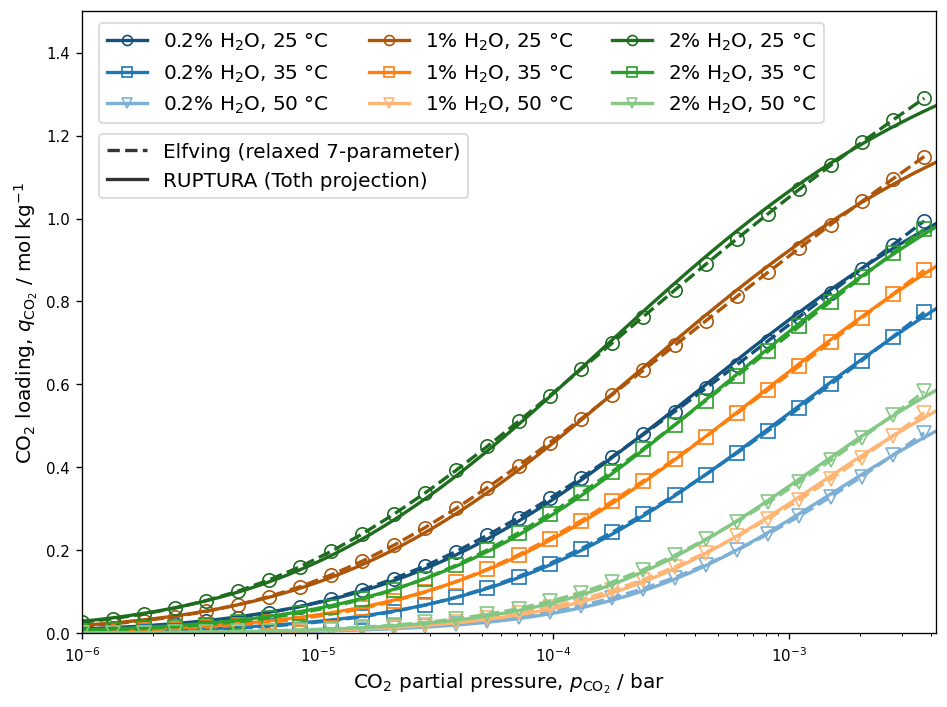

In [93]:
pressure_bar = np.geomspace(1e-6, 4.2e-3, 220)
temperatures = [298.15, 308.15, 323.15]
temperature_shades = {298.15: "dark", 308.15: "normal", 323.15: "light"}
humidities = [0.0016, 0.0095, 0.0190]
nominal_humidities = ["0.2%", "1%", "2%"]
markers = ['o', 's', 'v']

fig, ax = plt.subplots(figsize=(8, 6))
condition_handles = []
for index, (humidity, nominal) in enumerate(zip(humidities, nominal_humidities)):
    base = f"C{index}"
    for j, temperature in enumerate(temperatures):
        color = shade_level_color(base, temperature_shades[temperature])
        paper = np.array([
            sum(coadsorption_loading(MODELS["seven_relaxed"], temperature, pressure, humidity * 1.01325))
            for pressure in pressure_bar
        ])
        qmax, affinity, exponent, rms = fit_toth(pressure_bar.tolist(), paper.tolist())
        ruptura = np.array([toth_loading(qmax, affinity, exponent, pressure) for pressure in pressure_bar])
        ax.plot(pressure_bar[::8], paper[::8], color=color, linewidth=2.0, linestyle="--", marker=markers[j], markerfacecolor='none', markersize=8)
        ax.plot(pressure_bar, ruptura, color=color, linewidth=2.0)
        condition_handles.append(Line2D(
            [], [], color=color, linewidth=2,
            label=f"{nominal} H$_2$O, {temperature - 273.15:.0f} °C",
            marker=markers[j], markerfacecolor='none', markersize=6
        ))
ax.set_xscale("log")
ax.set_xlim(1e-6, 4.2e-3)
ax.set_ylim(0, 1.5)
ax.set_xlabel("CO$_2$ partial pressure, $p_{\\mathrm{CO_2}}$ / bar", fontsize=12)
ax.set_ylabel("CO$_2$ loading, $q_{\\mathrm{CO_2}}$ / mol kg$^{-1}$", fontsize=12)
condition_legend = ax.legend(
    handles=condition_handles, ncol=3, fontsize=12, loc=(0.02, 0.82)
)
ax.add_artist(condition_legend)
ax.legend(
    handles=[
        Line2D([], [], color="0.2", linewidth=2, linestyle="--", label="Elfving (relaxed 7-parameter)"),
        Line2D([], [], color="0.2", linewidth=2, label="RUPTURA (Toth projection)"),
    ],
    loc=(0.02, 0.7),
    fontsize=12
)
fig.tight_layout()
plt.show()


## Figure 5 - CO$_2$ breakthrough at 25-26 °C and 500 ml/min

Runs 1-3 use the measured humidities corresponding to the paper's three nominal setpoints. The temperature diagnostic uses the solid temperature at the grid point nearest the bed midpoint. The loading diagnostic is the arithmetic mean of total adsorbed CO$_2$ over every output grid point.

### Figure 5a-b reference - normalized CO$_2$ and H$_2$O breakthrough


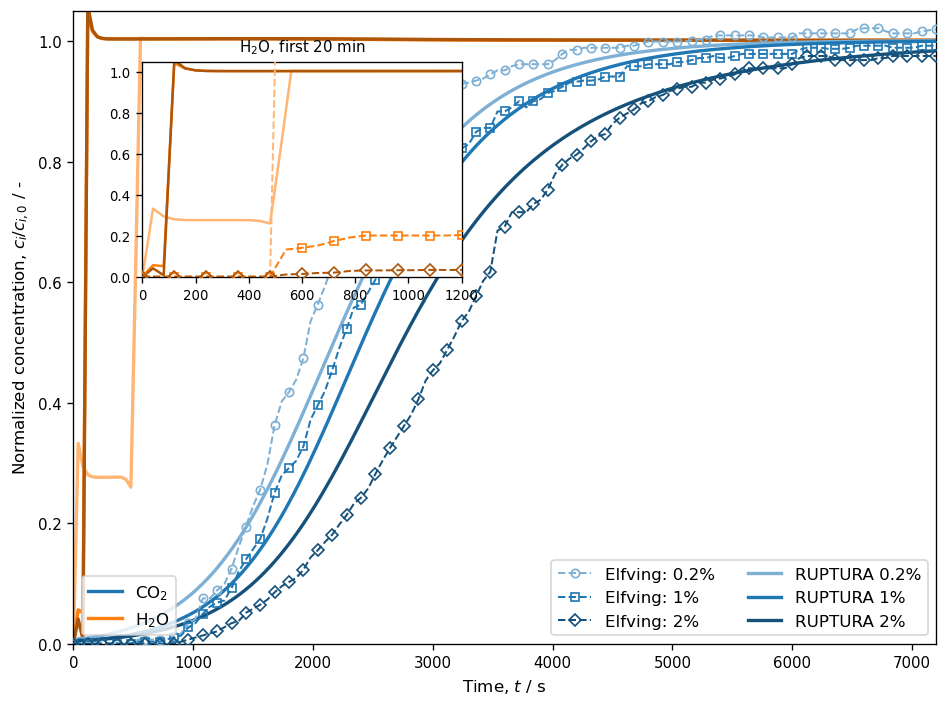

Condition,Run,Pixel t10 [s],RUPTURA t10 [s],Pixel t50 [s],RUPTURA t50 [s]
0.2% nominal / 0.16% measured,1,1262.6,1081.4,1945.4,2171.1
1% nominal / 0.95% measured,2,1337.4,1321.3,2237.4,2409.0
2% nominal / 1.90% measured,3,1779.7,1498.4,3153.3,2737.5


In [94]:
figure_5_specs = [
    ("0p2", "0.2% nominal / 0.16% measured", [1], "o"),
    ("1", "1% nominal / 0.95% measured", [2], "s"),
    ("2", "2% nominal / 1.90% measured", [3], "D"),
]
breakthrough_overlay(
    "figure_5a.csv",
    figure_5_specs,
    (0, 7200, 0, 400),
    legend_location="lower right",
)


### Figure 5c reference - midpoint solid temperature


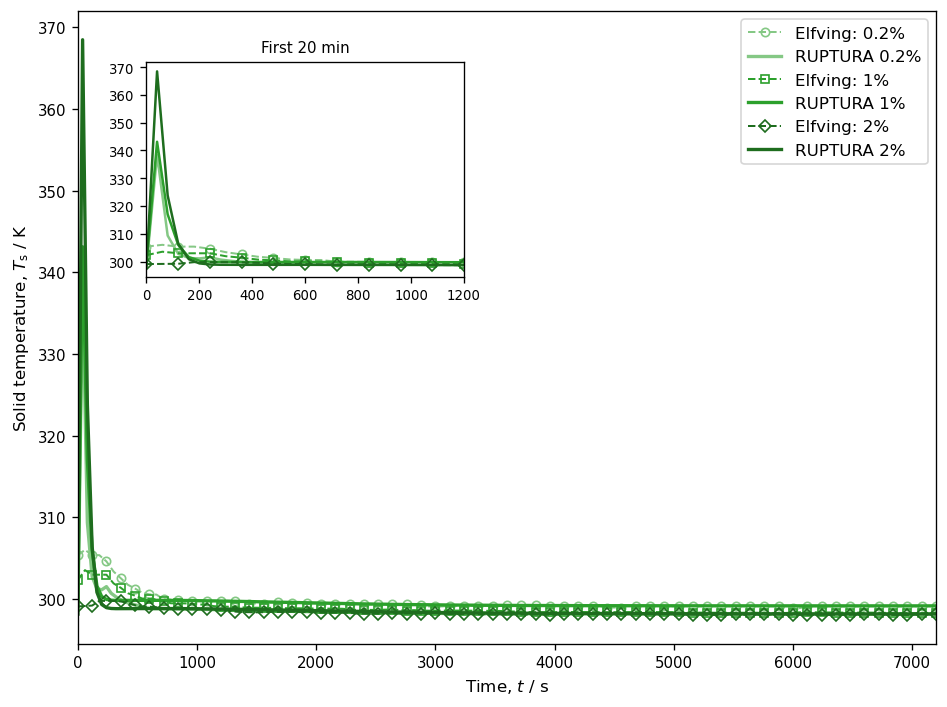

In [95]:
midpoint_temperature_plot(figure_5_specs, time_limit=7200, control_file="figure_5c.csv")

### Figure 5d reference - grid-averaged CO$_2$ loading


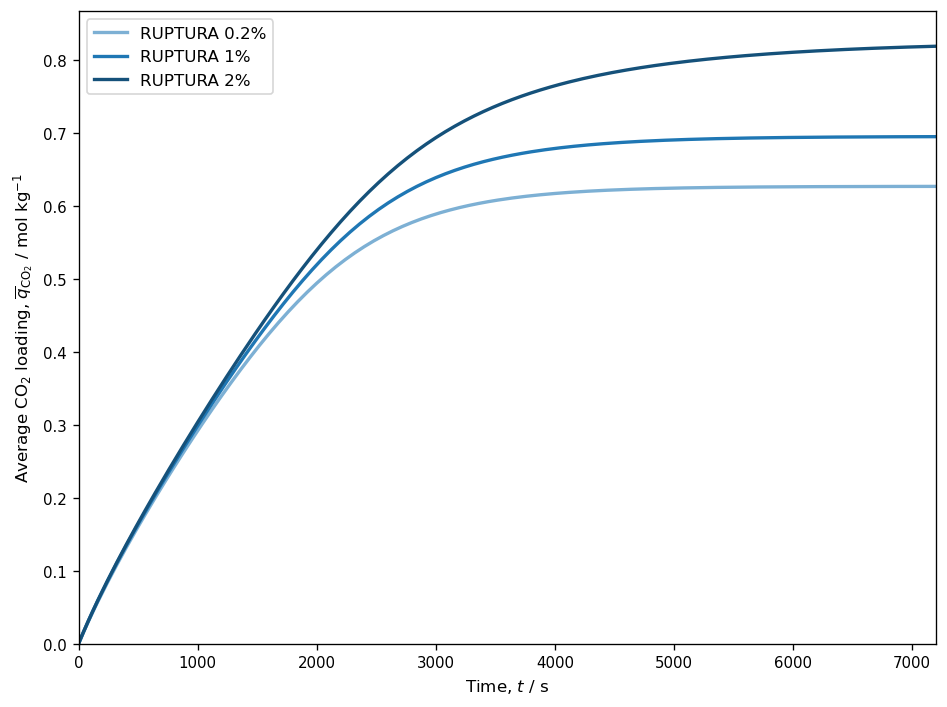

In [96]:
average_co2_loading_plot(figure_5_specs, time_limit=7200)


## Figure 6 - CO$_2$ breakthrough at 35 °C and 500 ml/min

Runs 4 and 5 represent the measured humidities corresponding to the nominal 1 and 2 vol-% setpoints. Temperature is sampled at the bed midpoint and CO$_2$ loading is averaged over all grid points.

### Figure 6a-b reference - normalized CO$_2$ and H$_2$O breakthrough


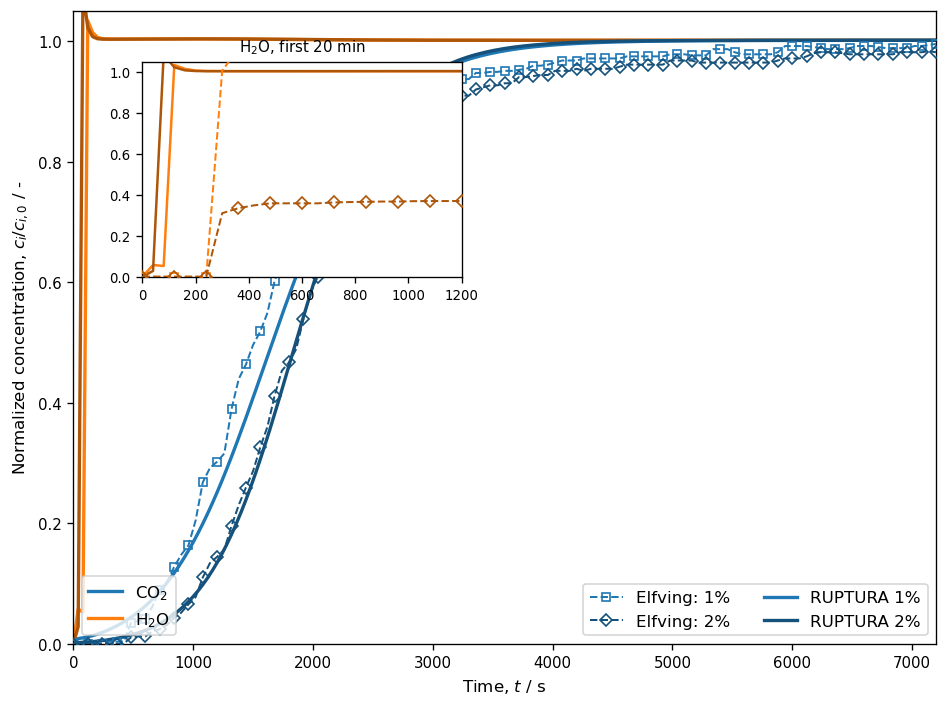

Condition,Run,Pixel t10 [s],RUPTURA t10 [s],Pixel t50 [s],RUPTURA t50 [s]
1% nominal / 0.95% measured,4,773.8,776.1,1511.0,1660.8
2% nominal / 1.90% measured,5,1061.9,1087.6,1873.2,1856.7


In [97]:
figure_6_specs = [
    ("1", "1% nominal / 0.95% measured", [4], "s"),
    ("2", "2% nominal / 1.90% measured", [5], "D"),
]
breakthrough_overlay(
    "figure_6a.csv",
    figure_6_specs,
    (0, 7200, 0, 400),
    legend_location="lower right",
)


### Figure 6c reference - midpoint solid temperature


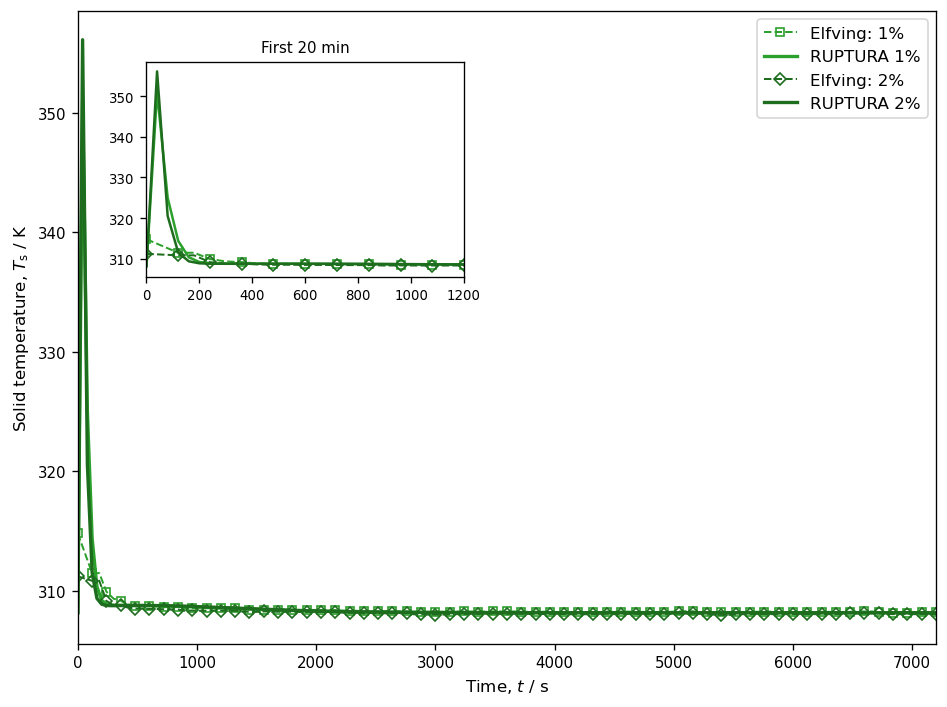

In [98]:
midpoint_temperature_plot(figure_6_specs, time_limit=7200, control_file="figure_6c.csv")

### Figure 6d reference - grid-averaged CO$_2$ loading


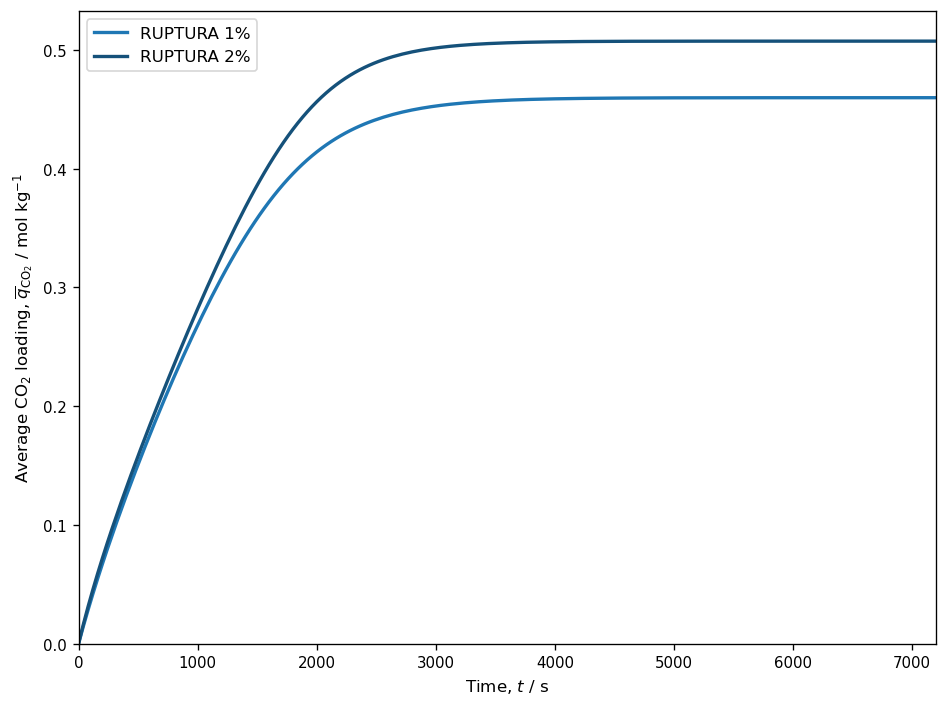

In [99]:
average_co2_loading_plot(figure_6_specs, time_limit=7200)


## Figure 7 - CO$_2$ breakthrough at 25-26 °C and 500 ml/min

Runs 6-8 use the bounded 7-parameter projection with `t1=t2=3` and the measured humidity values. Figure 7 in the paper does not include H$_2$O or temperature panels, so those two RUPTURA diagnostics are included here as requested.

### Figure 7a reference - normalized CO$_2$ and H$_2$O breakthrough


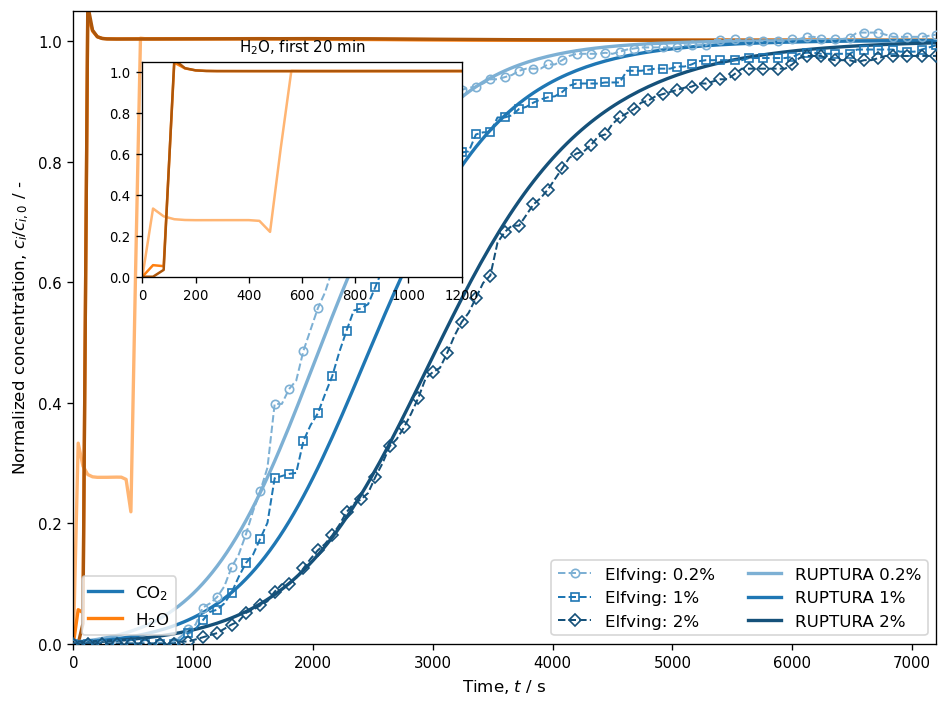

Condition,Run,Pixel t10 [s],RUPTURA t10 [s],Pixel t50 [s],RUPTURA t50 [s]
0.2% nominal / 0.16% measured,6,1269.3,1081.3,1943.9,2076.3
1% nominal / 0.95% measured,7,1355.2,1403.4,2246.9,2499.9
2% nominal / 1.90% measured,8,1808.0,1800.6,3157.4,3058.2


In [100]:
figure_7_specs = [
    ("0p2", "0.2% nominal / 0.16% measured", [6], "o"),
    ("1", "1% nominal / 0.95% measured", [7], "s"),
    ("2", "2% nominal / 1.90% measured", [8], "D"),
]
breakthrough_overlay(
    "figure_7a.csv",
    figure_7_specs,
    (0, 7200, 0, 400),
    legend_location="lower right",
)


### Figure 7 reference - midpoint solid temperature


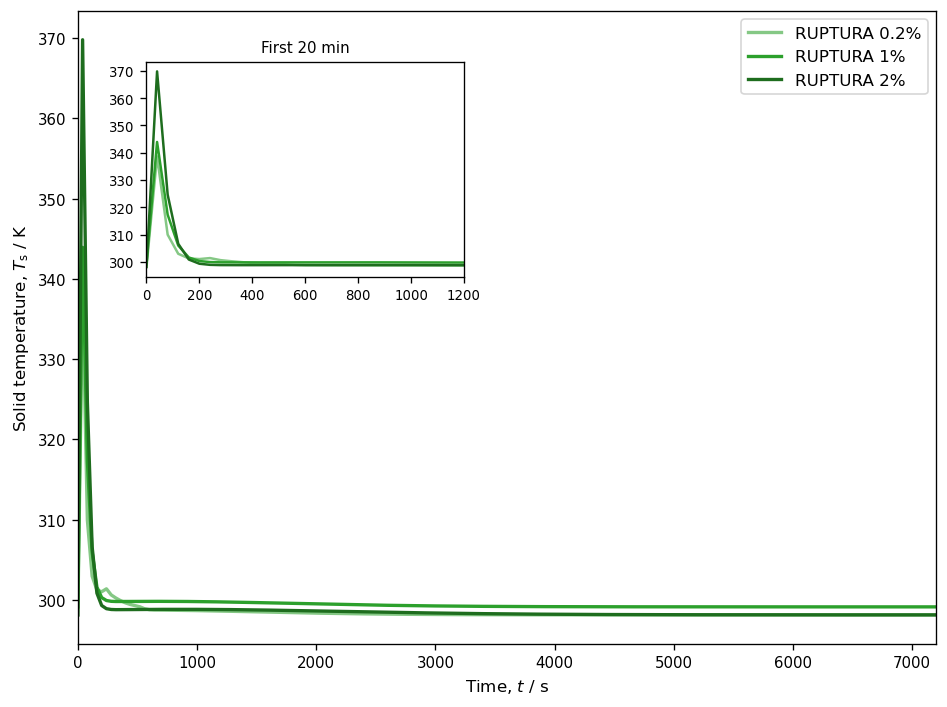

In [101]:
midpoint_temperature_plot(figure_7_specs, time_limit=7200)


### Figure 7b reference - grid-averaged CO$_2$ loading


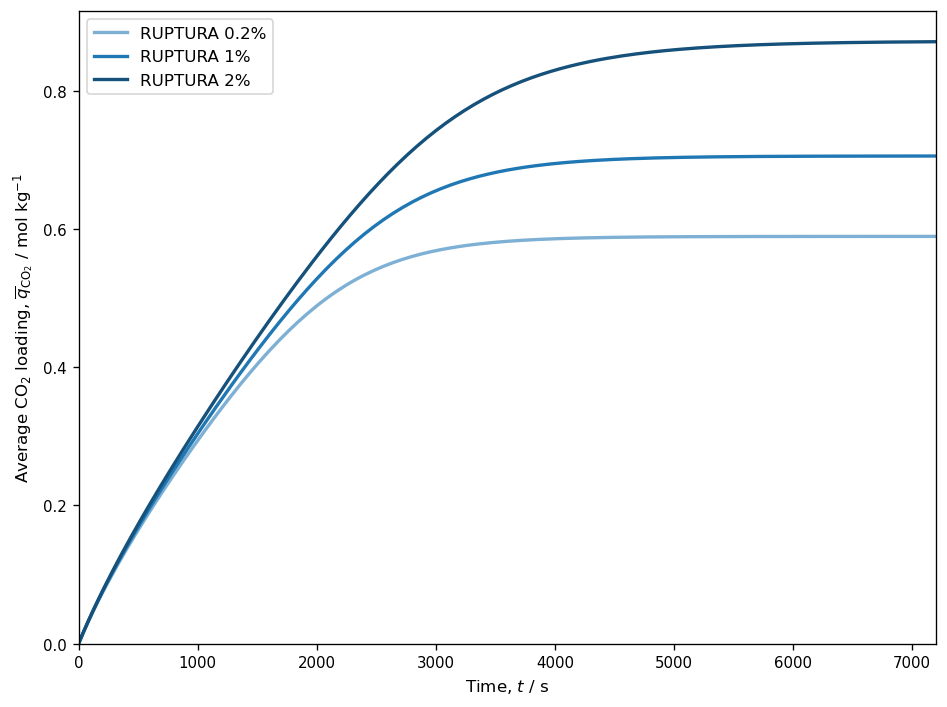

In [102]:
average_co2_loading_plot(figure_7_specs, time_limit=7200)


## Figure 8 - CO$_2$ breakthrough at 25 °C and 100 ml/min

Runs 10-11 compare the 5- and bounded 7-parameter RUPTURA projections against the same pixel-derived experiment. The breakthrough plot retains the paper inset's 0-27000 s window. The temperature and loading plots use the full available RUPTURA output horizon of 57600 s.

### Figure 8a-b reference - normalized CO$_2$ and H$_2$O breakthrough


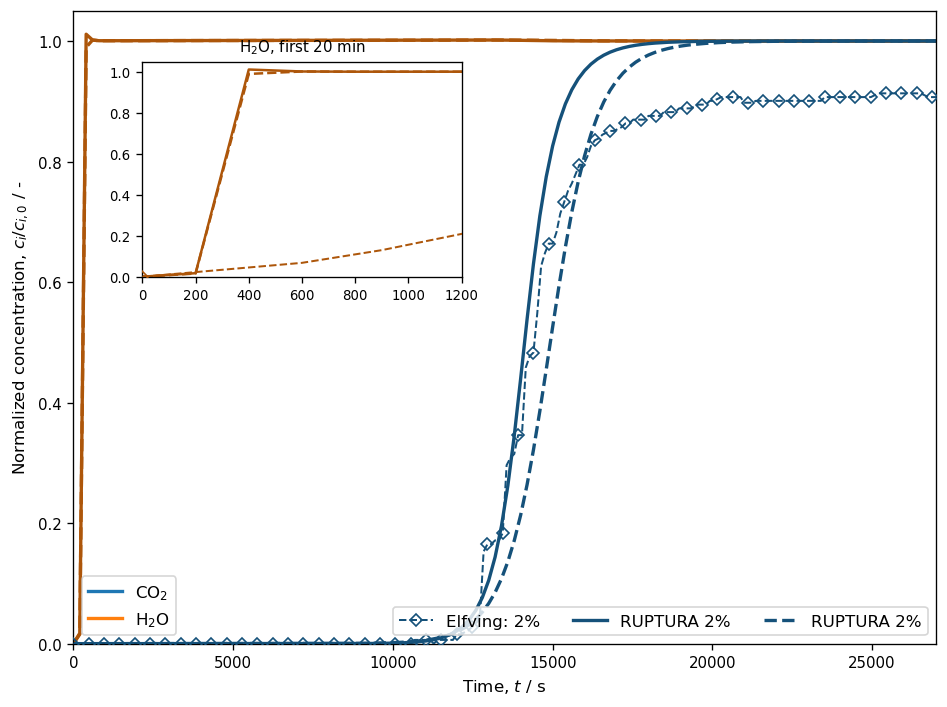

Condition,Run,Pixel t10 [s],RUPTURA t10 [s],Pixel t50 [s],RUPTURA t50 [s]
2% nominal / about 2% measured,10,12783.6,12964.4,14430.9,14122.3
2% nominal / about 2% measured,11,12783.6,13331.2,14430.9,14928.2


In [103]:
figure_8_specs = [
    ("experimental", "2% nominal / about 2% measured", [10, 11], "D"),
]
breakthrough_overlay(
    "figure_8a.csv",
    figure_8_specs,
    (0, 27000, 0, 400),
    legend_location="lower right",
)


### Figure 8c reference - midpoint solid temperature


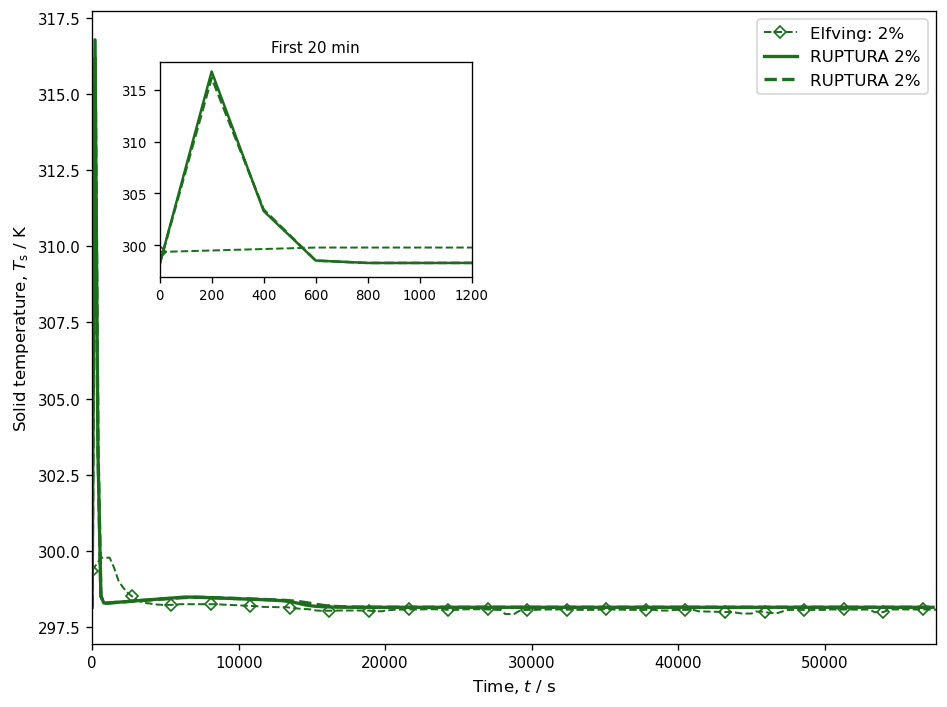

In [104]:
midpoint_temperature_plot(figure_8_specs, time_limit=57600, control_file="figure_8c.csv")

### Figure 8d reference - grid-averaged CO$_2$ loading


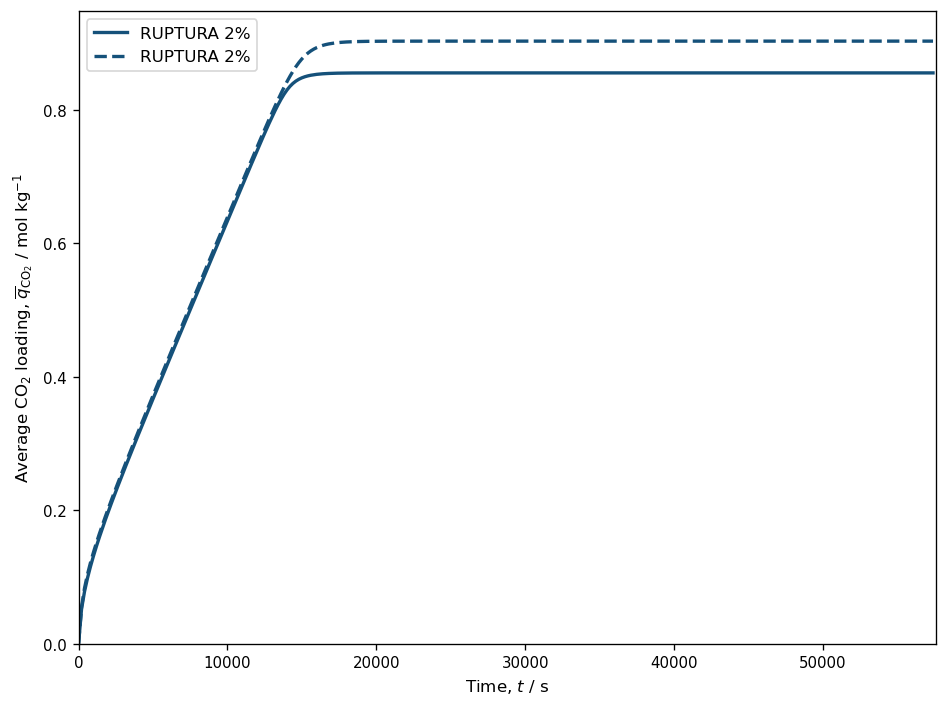

In [105]:
average_co2_loading_plot(figure_8_specs, time_limit=57600)


## Reading the overlays

- Markers are pixel-digitized Elfving CO$_2$ controls; lines are RUPTURA CO$_2$ and H$_2$O results.
- C0 identifies CO$_2$ and C1 identifies H$_2$O. Within each color family, 0.2%, 1%, and 2% humidity use light, normal, and dark shades with circle, square, and diamond markers.
- The temperature curves use solid temperature at the grid point nearest the bed midpoint and remain in kelvin.
- The adsorption curves average total CO$_2$ loading over all grid points at each output time.
- Figures 5-7 make the differences in breakthrough timing and front shape directly visible against reconstructed paper data.
- Figure 8 uses the paper's inset because the full 162000 s axis compresses the breakthrough transition into a narrow region.
- The tables compare 10% and 50% breakthrough times. The 1% level is intentionally omitted because it lies too close to the rendered baseline for reliable pixel recovery.
- Treat the recovered values as digitization-based controls, not original experimental precision.
